# Lab 5 - Day and Night Image Classification
## JS06 - Classification 2

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

### Objective
Perform binary image classification (day vs night) through data preprocessing, image resizing, color space conversion (RGB to HSV), average brightness feature extraction, threshold-based manual classification, and building an SVM model using Scikit-Learn.

## Step 0 - Import Libraries and Set Directories

In [1]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

%matplotlib inline

# Image directories
train_dir = 'images/training/'
test_dir = 'images/test/'

## Step 1 - Load Data and Visualize

In [2]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = [d for d in p.glob('*') if d.is_dir() and not d.name.startswith('.') and not d.name.startswith('__')]

    img_list = []
    for d in dirs:
        label = d.name
        for file in d.glob('*.jpg'):
            img = mpimg.imread(str(file))
            if img is not None:
                img_list.append((img, label))
    
    return img_list

# Load training data
train_img = load_dataset(train_dir)
print(f'Total training images loaded: {len(train_img)}')

Total training images loaded: 240


### Check First Data Entry and Random Size Check

In [3]:
# Check the first data tuple (image array and label)
print('Type of first entry:', type(train_img[0]))
print('Image array shape:', train_img[0][0].shape)
print('Label:', train_img[0][1])

# Random size checking
np.random.seed(42)
pick_random = np.random.randint(0, len(train_img))
print(f'Random Image index {pick_random}:')
print(f'Shape: {train_img[pick_random][0].shape}')

Type of first entry: <class 'tuple'>
Image array shape: (458, 800, 3)
Label: day
Random Image index 102:
Shape: (555, 800, 3)


### Visualize an Image at Random

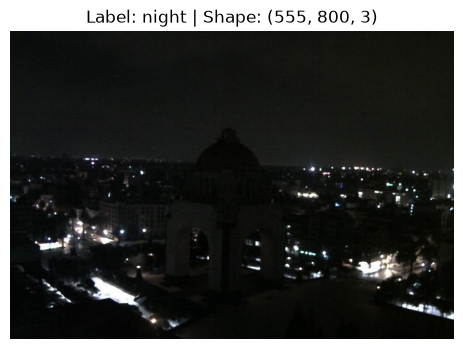

In [4]:
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    
    plt.figure(figsize=(6, 4))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f'Label: {label} | Shape: {img.shape}')
    plt.show()

random_img_viz(train_img)

## Step 3 - Data Preprocessing
We standardize the image sizes to $1100 \times 600$ pixels and encode labels numerically: `'day'` as `1` and `'night'` as `0`.

In [5]:
def standarized_input(image):
    # resize to w: 1100, h: 600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

def label_encoder(label):
    # Encode the label: day as 1; night as 0
    num_val = 0
    if label == 'day' or label == 1:
        num_val = 1
    return num_val

def preprocess(img_list):
    std_img_list = []
    for item in img_list:
        image = item[0]
        label = item[1]
        std_img = standarized_input(image)
        img_label = label_encoder(label)
        std_img_list.append((std_img, img_label))
    return std_img_list

train_std_img_list = preprocess(train_img)

# Random size checking on preprocessed images
pick_random = np.random.randint(0, len(train_std_img_list))
print(f'Preprocessed Image index {pick_random}')
print(f'Shape (height, width, channels): {train_std_img_list[pick_random][0].shape}')

Preprocessed Image index 92
Shape (height, width, channels): (600, 1100, 3)


### Visual Inspection of Preprocessed Image

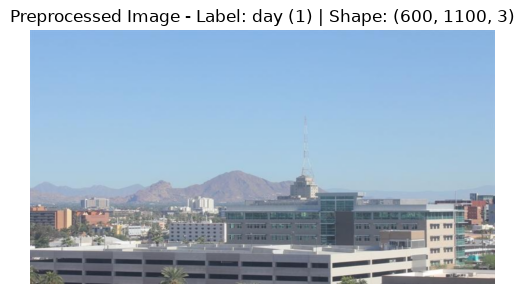

In [6]:
rand_num = np.random.randint(0, len(train_std_img_list))
img = train_std_img_list[rand_num][0]
label = train_std_img_list[rand_num][1]
label_str = 'day' if label == 1 else 'night'

plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.axis('off')
plt.title(f'Preprocessed Image - Label: {label_str} ({label}) | Shape: {img.shape}')
plt.show()

## Step 4 - Feature Extraction (Average Brightness)
We convert the RGB image to HSV color space and compute the average value of the V (Value / brightness) channel.

Image 106 (day)
Avg Brightness: 135.2176


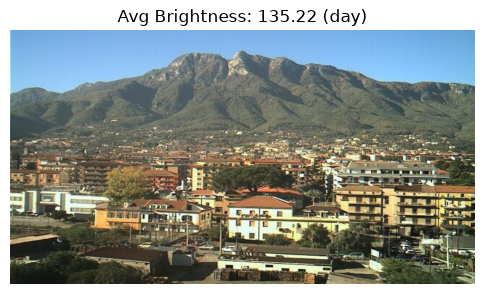

In [7]:
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    # Calculate the average of brightness from V channel (index 2)
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area
    return avg

# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))
feature_img = train_std_img_list[rand_img][0]
avg_img = avg_brightness(feature_img)
actual_lbl = 'day' if train_std_img_list[rand_img][1] == 1 else 'night'

print(f'Image {rand_img} ({actual_lbl})')
print(f'Avg Brightness: {avg_img:.4f}')

plt.figure(figsize=(6, 4))
plt.imshow(feature_img)
plt.axis('off')
plt.title(f'Avg Brightness: {avg_img:.2f} ({actual_lbl})')
plt.show()

## Step 5 - Classification using Threshold Method
Predict `1` (day) if average brightness > threshold, else `0` (night).

Image 71
Actual label: 1 (day)
Predicted label: 0 (night)


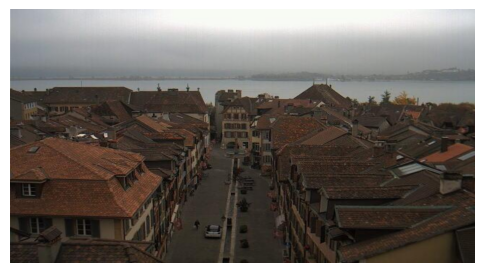

In [8]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    pred = 0
    if avg > threshold:
        pred = 1
    return pred

# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)
actual = train_std_img_list[rand_img][1]

actual_str = 'day' if actual == 1 else 'night'
pred_str = 'day' if pred == 1 else 'night'
print(f'Image {rand_img}')
print(f'Actual label: {actual} ({actual_str})')
print(f'Predicted label: {pred} ({pred_str})')

plt.figure(figsize=(6, 4))
plt.imshow(train_std_img_list[rand_img][0])
plt.axis('off')
plt.show()

## Step 6 - Manual Evaluation with Threshold

In [9]:
def evaluate(img_list, threshold):
    miss_labels = []
    for file in img_list:
        img = file[0]
        label = file[1]
        pred_label = predict_label(img, threshold)
        if pred_label != label:
            miss_labels.append((img, pred_label, label))
    
    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img
    print(f'Threshold: {threshold} | Total: {total_img} | Misclassified: {len(miss_labels)} | Accuracy: {accuracy:.4f}')
    return accuracy

print('--- Evaluation on Training Data ---')
evaluate(train_std_img_list, threshold=120)

print('\n--- Evaluation on Test Data ---')
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)
evaluate(test_std_img_list, threshold=120)

--- Evaluation on Training Data ---


Threshold: 120 | Total: 240 | Misclassified: 38 | Accuracy: 0.8417

--- Evaluation on Test Data ---


Threshold: 120 | Total: 160 | Misclassified: 21 | Accuracy: 0.8688


0.86875

## Classification with Support Vector Machine (SVM)
Instead of manually picking an arbitrary threshold, we train a Support Vector Classifier.

### Alternative Step 4 - Constructing Feature Vectors

In [10]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []
    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]
        avg_list.append(img_avg)
        labels.append(img_label)
    
    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])
    return df

train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Train feature table shape: {train_avg_img.shape}')
print(train_avg_img.head())

test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'\nTest feature table shape: {test_avg_img.shape}')
print(test_avg_img.head())

Train feature table shape: (240, 2)
   AVG_BRIGHT  LABELS
0  175.092992     1.0
1  192.907867     1.0
2  132.133823     1.0
3  199.749191     1.0
4  109.947203     1.0



Test feature table shape: (160, 2)
   AVG_BRIGHT  LABELS
0  194.228062     1.0
1  157.826662     1.0
2  201.607444     1.0
3  191.237441     1.0
4  188.119652     1.0


### Step 5 - Build and Train SVM Model

In [11]:
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

model = SVC(kernel='rbf')
model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### Step 6 - Model Evaluation

In [12]:
y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train: {acc_train:.4f} ({acc_train * 100:.2f}%)')
print(f'Accuracy on test : {acc_test:.4f} ({acc_test * 100:.2f}%)')

Accuracy on train: 0.8583 (85.83%)
Accuracy on test : 0.9000 (90.00%)
